Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0179
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 4.8455e-04
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 4.6067e-04
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 4.5094e-04
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 4.4477e-04
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 4.2857e-04
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 4.2056e-04
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 4.0325e-04
Epoch 9/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 4.0257e-04
Epoch 10/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 3.9487e-04
MAE: 668.03


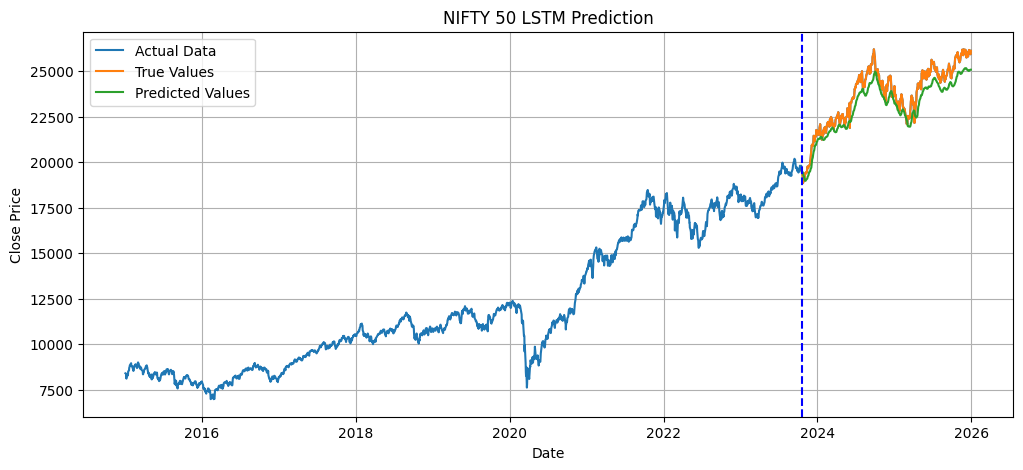

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# 1. Load dataset
data = pd.read_csv('IMDB Dataset.csv', skiprows=[1, 2])

close = data['Close'].astype('float32').values.reshape(-1, 1)
dates = pd.to_datetime(data['Price'])

# 2. Normalize data
split = int(len(close) * 0.8)

scaler = MinMaxScaler()
scaler.fit(close[:split])
scaled = scaler.transform(close)

# 3. Create sequences
X, y = [], []

for i in range(60, len(scaled)):
    X.append(scaled[i-60:i])
    y.append(scaled[i])

X = np.array(X)
y = np.array(y)

X_train, X_test = X[:split-60], X[split-60:]
y_train, y_test = y[:split-60], y[split-60:]

# 4. Build and compile model
model = Sequential([
    Input(shape=(60, 1)),
    LSTM(50),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

# 5. Train model
model.fit(X_train, y_train, epochs=10, batch_size=32)

# 6. Predict
pred = model.predict(X_test, verbose=0)

pred = scaler.inverse_transform(pred)
actual = scaler.inverse_transform(y_test)

# 7. Calculate MAE
mae = mean_absolute_error(actual, pred)
print("MAE:", round(mae, 2))

# 8. Plot results
plt.figure(figsize=(12, 5))

plt.plot(dates, close, label='Actual Data')
plt.plot(dates.iloc[split:], actual, label='True Values')
plt.plot(dates.iloc[split:], pred, label='Predicted Values')
plt.axvline(dates.iloc[split], color='blue', linestyle='--')

plt.title('NIFTY 50 LSTM Prediction')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid()
plt.show()